# **Time Series and Forecasting - Final Project**
| Matheus Hirakawa Bissacot (up202106708) |
Bernardo Gil Alves Salgado (up202004493) |
Michal Dawid Kowalski (up202401554) |

## 1. Uploading Dataset

**Dataset:** 'Hourly Energy Consumption' link: https://www.kaggle.com/datasets/robikscube/hourly-energy-consumption/data

**Brief:** Over 10 years of hourly energy consumption data from PJM in Megawatts. 

**Characterisitcs:** PJM Hourly Energy Consumption Data.

PJM Interconnection LLC (PJM) is a regional transmission organization (RTO) in the United States. It is part of the Eastern Interconnection grid operating an electric transmission system serving all or parts of Delaware, Illinois, Indiana, Kentucky, Maryland, Michigan, New Jersey, North Carolina, Ohio, Pennsylvania, Tennessee, Virginia, West Virginia, and the District of Columbia.

The hourly power consumption data comes from PJM's website and are in megawatts (MW).

The regions have changed over the years so data may only appear for certain dates per region.

In [58]:
# Importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from scipy.fft import fft, fftfreq
from scipy.signal import periodogram
from statsmodels.tsa.stattools import acf
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller, kpss
from pandas import to_datetime
import pmdarima as pm
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.statespace.sarimax import SARIMAX

- Electricity usage for the **American Electric Power**

In [2]:
# Upload dataset AEP_hourly.csv
df_aep = pd.read_csv('archive/AEP_hourly.csv')

df_aep.set_index('Datetime', inplace =True) # Set datatime as the Dataframe index
df_aep.index = pd.to_datetime(df_aep.index) # Datatime format
df_aep = df_aep.sort_index() # Sort indexes

In [3]:
df_aep.head(5) # Display first 5 rows

,AEP_MW
Datetime,
2004-10-01 01:00:00,12379.0
2004-10-01 02:00:00,11935.0
2004-10-01 03:00:00,11692.0
2004-10-01 04:00:00,11597.0
2004-10-01 05:00:00,11681.0


In [4]:
df_aep.info() # Basic Dataset info

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 121273 entries, 2004-10-01 01:00:00 to 2018-08-03 00:00:00
Data columns (total 1 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   AEP_MW  121273 non-null  float64
dtypes: float64(1)
memory usage: 1.9 MB


In [5]:
# Check the time range
min_time = df_aep.index.min()
max_time = df_aep.index.max()
print ('Time range:\n')
print(f" Start Time: {min_time}")
print(f" End Time: {max_time}")
print(f" Time Range: {max_time - min_time}")

Time range:

 Start Time: 2004-10-01 01:00:00
 End Time: 2018-08-03 00:00:00
 Time Range: 5053 days 23:00:00


In [6]:
# Missing values checker
df_aep.isna().sum()

AEP_MW    0
dtype: int64

- No missing values in the dataset.

In [7]:
df_aep.describe() # Statistical Characteristics

,AEP_MW
count,121273.000000
mean,15499.513717
std,2591.399065
min,9581.000000
25%,13630.000000
50%,15310.000000
75%,17200.000000
max,25695.000000


## 2. Data Visualisation & Features Extraction

In this section, we carry out the dataset visualization which is a critical step in time series analysis. It helps us understand the nature of the data and identify key patterns or characteristics.

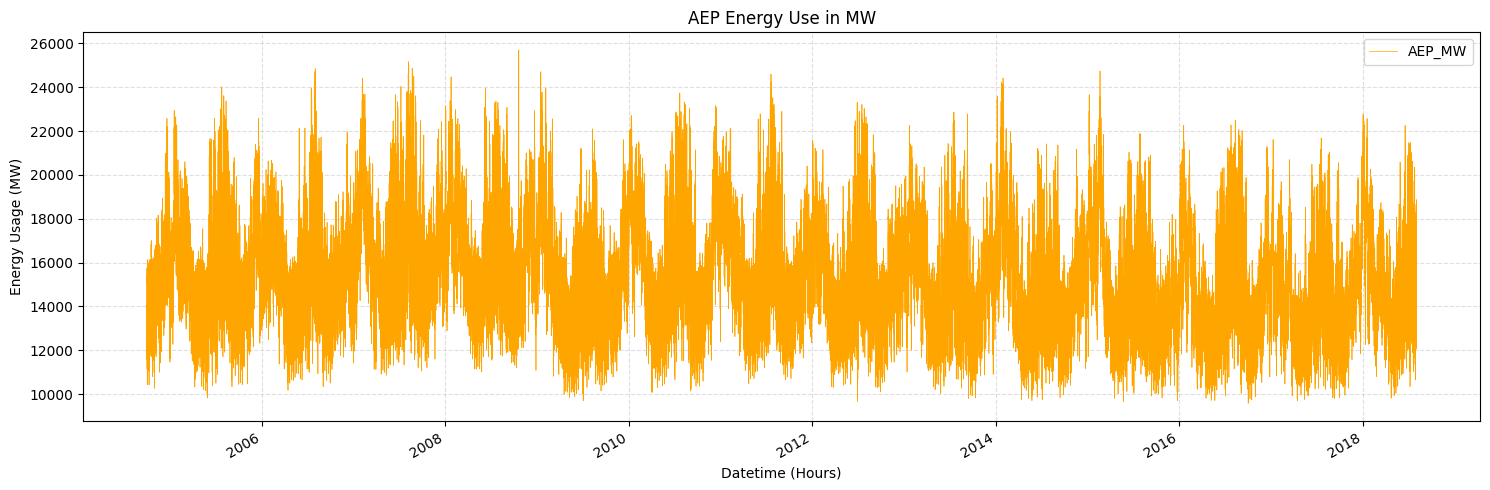

In [8]:
# Timeserie diagram
df_aep.plot(
    figsize=(15, 5),
    color='orange',
    linewidth=0.5,
    title='AEP Energy Use in MW',
    xlabel='Datetime (Hours)',
    ylabel='Energy Usage (MW)'
)
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

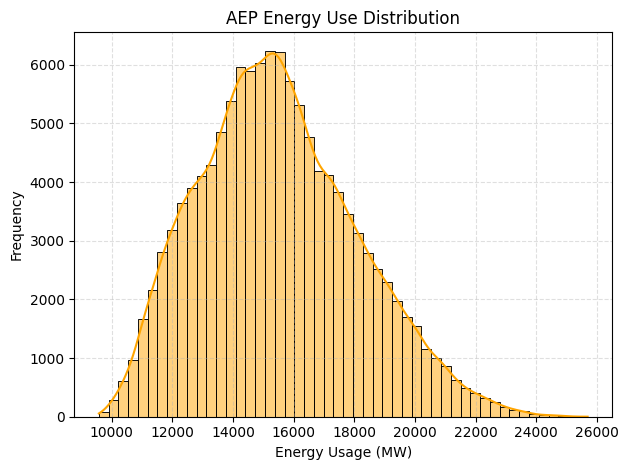

In [9]:
# Energy Usage Distribution
sns.histplot(
    data=df_aep, 
    x='AEP_MW', 
    kde=True, 
    bins=50, 
    color='orange', 
)

plt.title('AEP Energy Use Distribution')
plt.xlabel('Energy Usage (MW)')
plt.ylabel('Frequency')
plt.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

### Periodogram Analysis

The purpose is to identify dominant frequencies in a time series, revealing cyclic or seasonal patterns. It works by transforming the time series data into the frequency domain, allowing us to spot repeating cycles or trends over regular intervals. This is useful for detecting underlying periodic behaviors, such as monthly cycles, in the data.

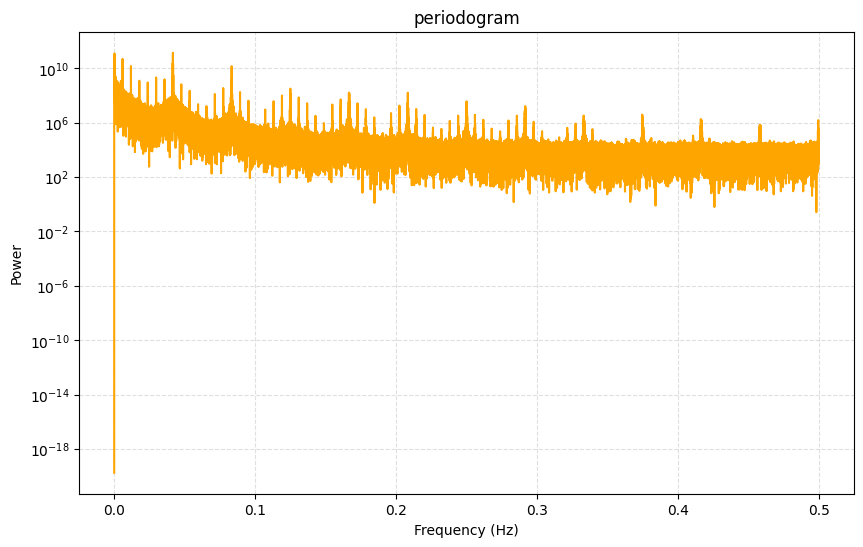

In [10]:
# Compute the periodogram
frequencies, power = periodogram(df_aep['AEP_MW'].dropna(), fs=1)

# Plot the periodogram
plt.figure(figsize=(10, 6))
plt.semilogy(frequencies, power, color='orange')
plt.title('periodogram')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Power')
plt.grid(True, linestyle='--', alpha=0.4)
plt.show()

The periodogram displays frequency on the x-axis (in Hertz) and power on the y-axis, showing the strength of signals at each frequency. Peaks indicate significant frequencies, suggesting periodic or seasonal patterns in the time series. While the periodogram doesn’t directly influence ARIMA parameter selection, it highlights trends or seasonality, which may require differencing the data to achieve stationarity before applying ARIMA.

### Feature Creation

This process involves generating new variables from the time series data to highlight patterns, trends, and seasonality, helping improve model performance by providing more informative inputs. The code adds features such as the hour of the day, day of the week, month, and year to capture time-related information. Additionally, it introduces a season feature, categorizing each month into one of four seasons (spring, summer, autumn, or winter), based on the month values.

In [11]:
df_aep['hour']=df_aep.index.hour     # hours
df_aep['day']=df_aep.index.dayofweek # days, where: 0 - Monday, 1 - Tuesday, 2 - Wednesday, 3 - Thrusday, 4 - Friday, 5 - Saturday, 6 - Sunday
df_aep['month']=df_aep.index.month   # months
df_aep['year']=df_aep.index.year     # years

# Function to get seasons
def get_season(month):
    if month in [12, 1, 2]:
        return 3
    if month in [3, 4, 5]:
        return 0
    if month in [6, 7, 8]:
        return 1
    if month in [9, 10, 11]:
        return 2

df_aep['season'] = df_aep['month'].apply(get_season) # seasons, where: 0 - spring, 1 - summer, 2 - autumn, 3 - winter


In [12]:
df_aep.head(5) # Feautres Display

,AEP_MW,hour,day,month,year,season
Datetime,,,,,,
2004-10-01 01:00:00,12379.0,1,4,10,2004,2
2004-10-01 02:00:00,11935.0,2,4,10,2004,2
2004-10-01 03:00:00,11692.0,3,4,10,2004,2
2004-10-01 04:00:00,11597.0,4,4,10,2004,2
2004-10-01 05:00:00,11681.0,5,4,10,2004,2


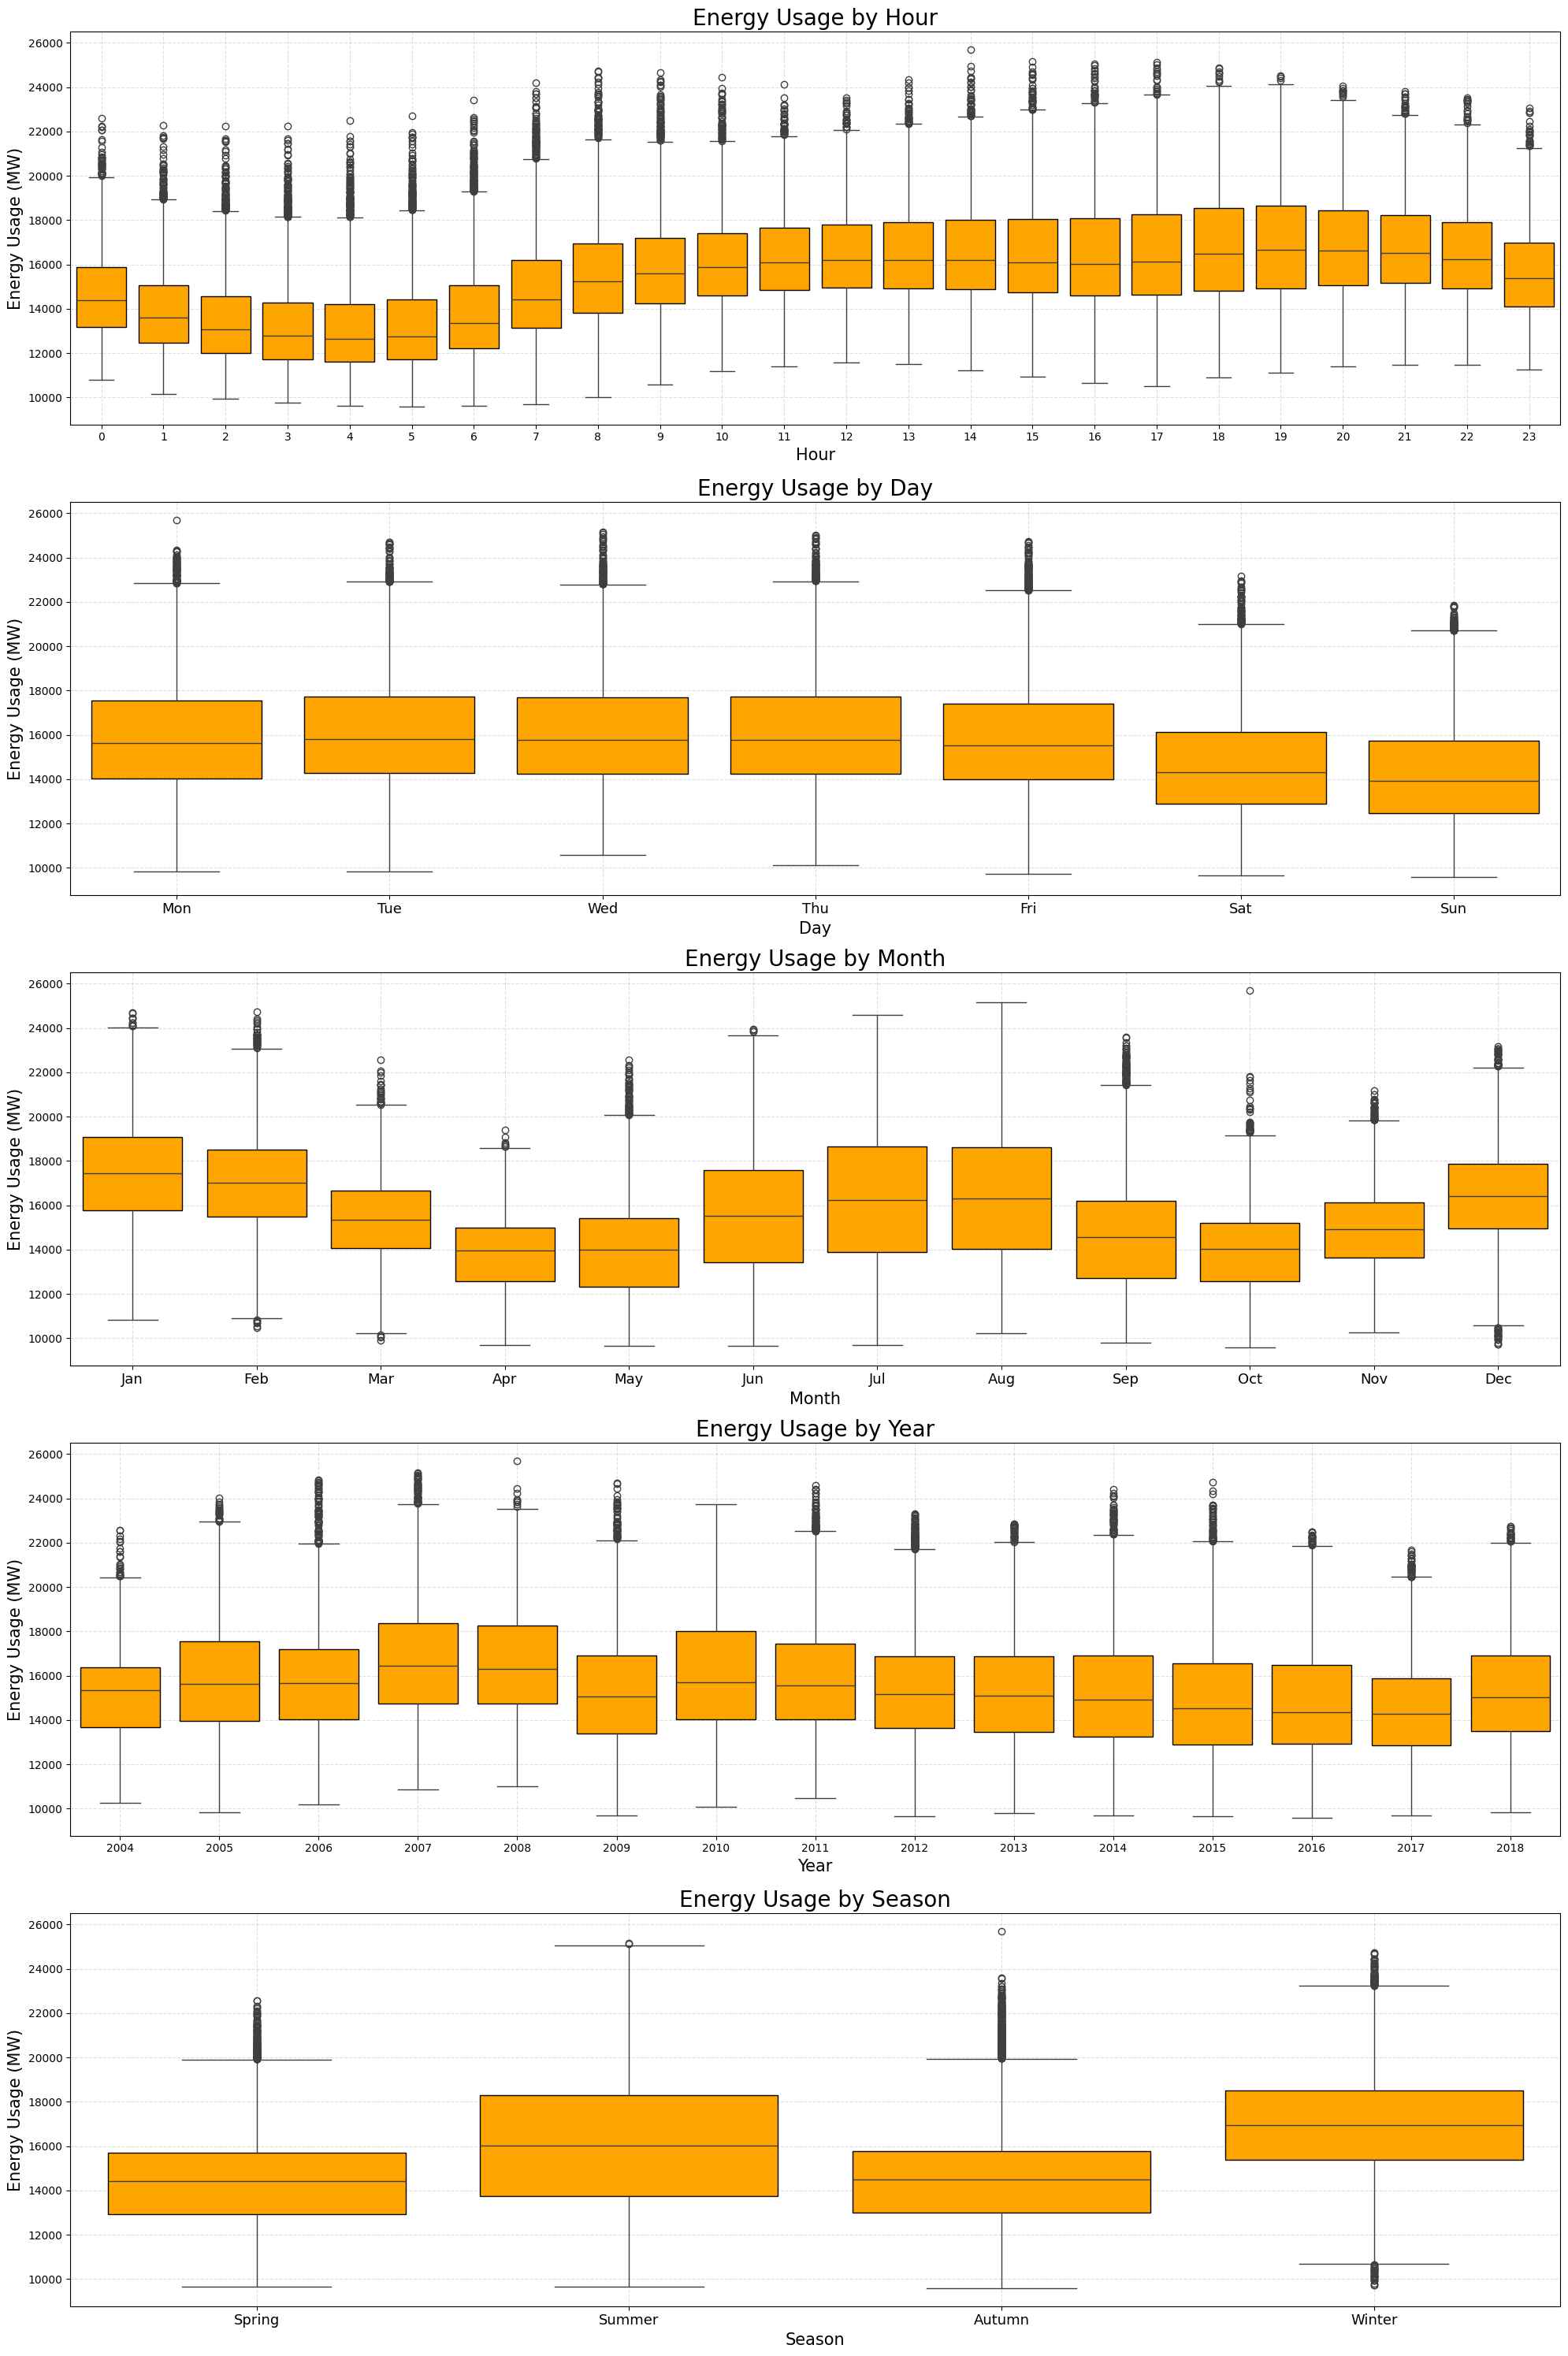

In [13]:
# Boxplots
fig, axes = plt.subplots(5, 1, figsize=(20, 30), sharex=False)

# Energy Usage by Hour
sns.boxplot(data=df_aep, x='hour', y='AEP_MW', ax=axes[0], boxprops=dict(facecolor='orange', edgecolor='black'))
axes[0].set_title('Energy Usage by Hour', fontsize=20)
axes[0].set_xlabel('Hour', fontsize = 15)
axes[0].set_ylabel('Energy Usage (MW)', fontsize = 15)
axes[0].grid(True, linestyle='--', alpha=0.4)

# Energy Usage by Day
sns.boxplot(data=df_aep, x='day', y='AEP_MW', ax=axes[1], boxprops=dict(facecolor='orange', edgecolor='black'))
axes[1].set_title('Energy Usage by Day', fontsize=20)
axes[1].set_xlabel('Day', fontsize = 15)
axes[1].set_ylabel('Energy Usage (MW)', fontsize = 15)
axes[1].set_xticks(range(0, 7))
axes[1].set_xticklabels(
    ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'], fontsize = 13)
axes[1].grid(True, linestyle='--', alpha=0.4)

# Energy Usage by Month
sns.boxplot(data=df_aep, x='month', y='AEP_MW', ax=axes[2], boxprops=dict(facecolor='orange', edgecolor='black'))
axes[2].set_title('Energy Usage by Month', fontsize=20)
axes[2].set_xlabel('Month', fontsize = 15)
axes[2].set_ylabel('Energy Usage (MW)', fontsize = 15)
axes[2].set_xticks(range(0, 12))
axes[2].set_xticklabels(
    ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 
    'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'], fontsize = 13)
axes[2].grid(True, linestyle='--', alpha=0.4)

# Energy Usage by Year
sns.boxplot(data=df_aep, x='year', y='AEP_MW', ax=axes[3], boxprops=dict(facecolor='orange', edgecolor='black'))
axes[3].set_title('Energy Usage by Year', fontsize=20)
axes[3].set_xlabel('Year', fontsize = 15)
axes[3].set_ylabel('Energy Usage (MW)', fontsize = 15)
axes[3].grid(True, linestyle='--', alpha=0.4)

# Energy Usage by Season
sns.boxplot(data=df_aep, x='season', y='AEP_MW', ax=axes[4], boxprops=dict(facecolor='orange', edgecolor='black'))
axes[4].set_title('Energy Usage by Season', fontsize=20)
axes[4].set_xlabel('Season', fontsize = 15)
axes[4].set_ylabel('Energy Usage (MW)', fontsize = 15)
axes[4].set_xticks(range(0, 4))
axes[4].set_xticklabels(
    ['Spring', 'Summer', 'Autumn', 'Winter'], fontsize = 13)
axes[4].grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

(Brief Analysis based on the report)

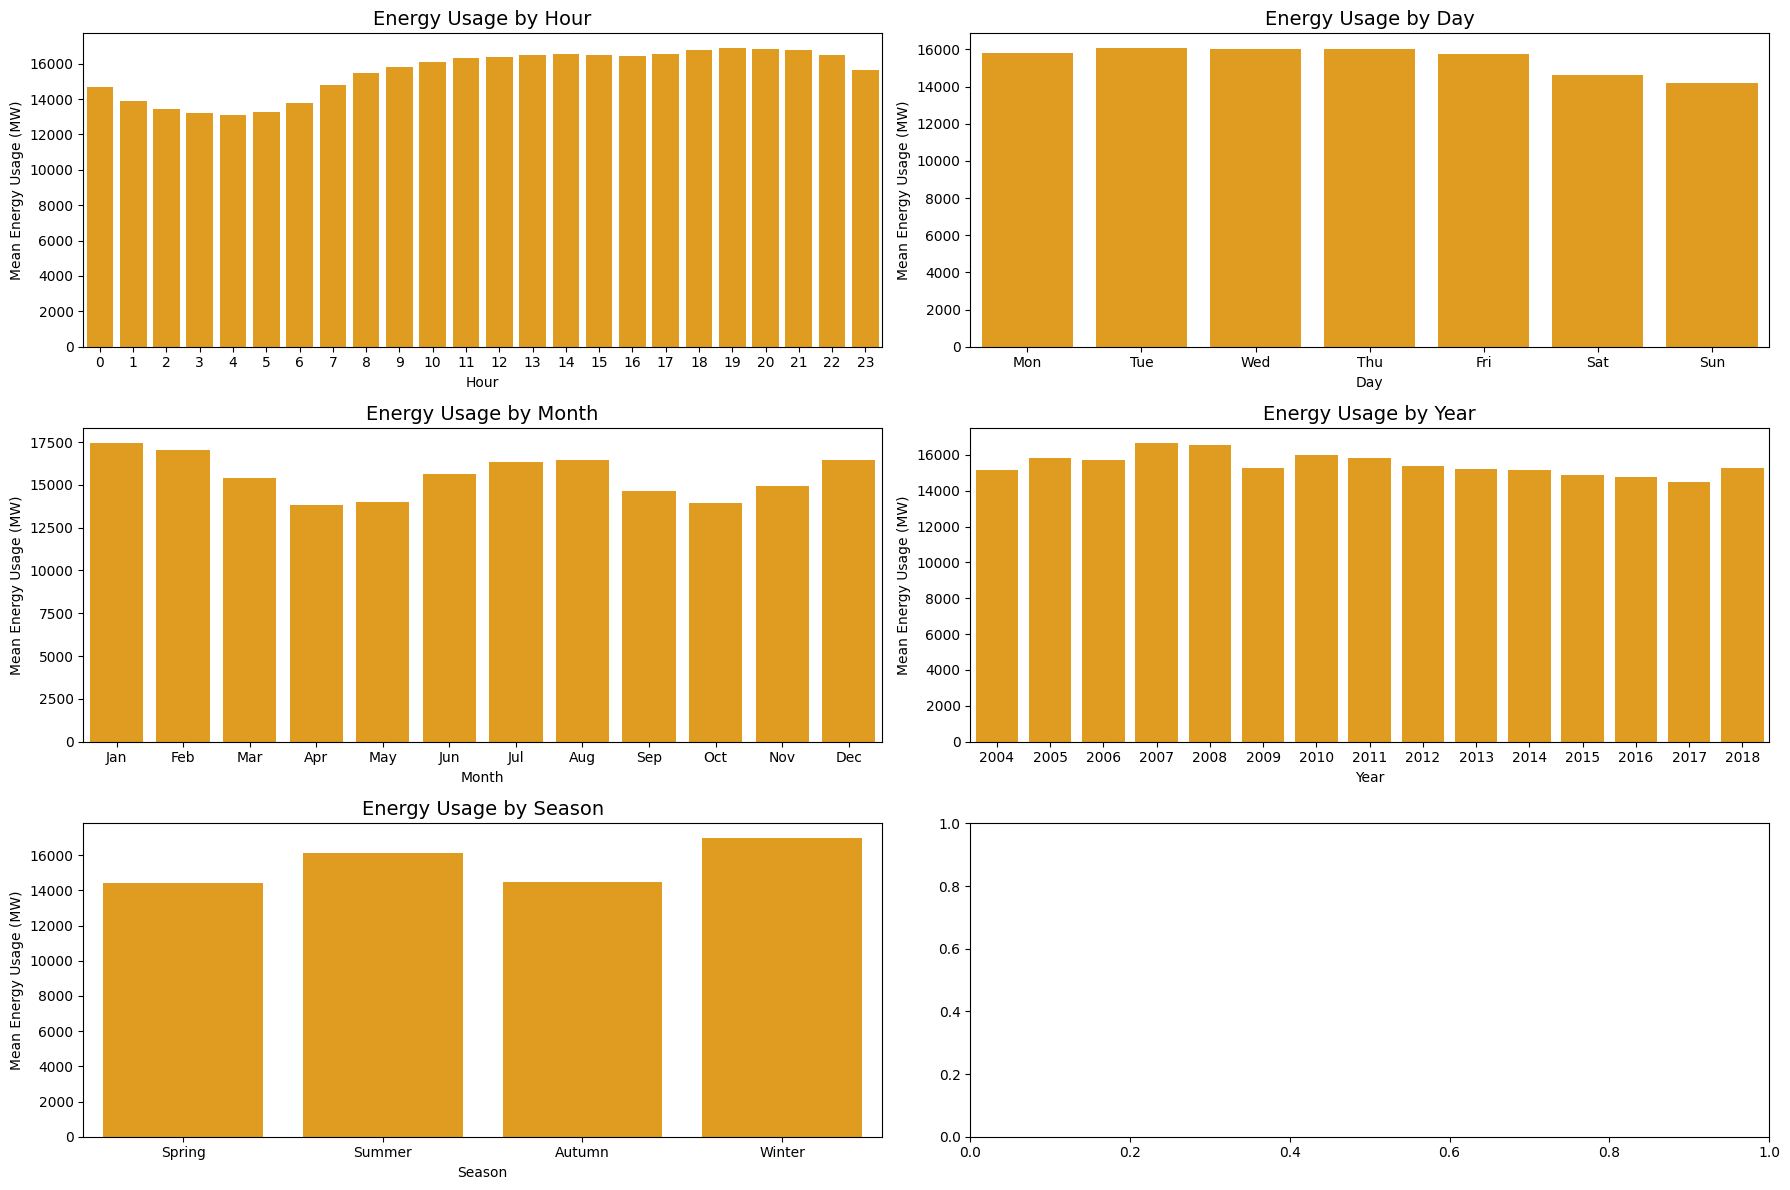

In [14]:
fig, axes = plt.subplots(3, 2, figsize=(18, 12))
axes = axes.flatten()

sns.barplot(data=df_aep, x='hour', y='AEP_MW', estimator=np.mean, errorbar=None, ax=axes[0], color='orange')
axes[0].set_title('Energy Usage by Hour', fontsize=14)
axes[0].set_xlabel('Hour')
axes[0].set_ylabel('Mean Energy Usage (MW)')

sns.barplot(data=df_aep, x='day', y='AEP_MW', estimator=np.mean, errorbar=None, ax=axes[1], color='orange')
axes[1].set_title('Energy Usage by Day', fontsize=14)
axes[1].set_xlabel('Day')
axes[1].set_ylabel('Mean Energy Usage (MW)')
axes[1].set_xticks(range(0, 7))
axes[1].set_xticklabels(['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'])


sns.barplot(data=df_aep, x='month', y='AEP_MW', estimator=np.mean, errorbar=None, ax=axes[2], color='orange')
axes[2].set_title('Energy Usage by Month', fontsize=14)
axes[2].set_xlabel('Month')
axes[2].set_ylabel('Mean Energy Usage (MW)')
axes[2].set_xticks(range(0, 12))
axes[2].set_xticklabels(['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])

sns.barplot(data=df_aep, x='year', y='AEP_MW', estimator=np.mean, errorbar=None, ax=axes[3], color='orange')
axes[3].set_title('Energy Usage by Year', fontsize=14)
axes[3].set_xlabel('Year')
axes[3].set_ylabel('Mean Energy Usage (MW)')

sns.barplot(data=df_aep, x='season', y='AEP_MW', estimator=np.mean, errorbar=None, ax=axes[4], color='orange')
axes[4].set_title('Energy Usage by Season', fontsize=14)
axes[4].set_xlabel('Season')
axes[4].set_ylabel('Mean Energy Usage (MW)')
axes[4].set_xticks([0, 1, 2, 3])
axes[4].set_xticklabels(['Spring', 'Summer', 'Autumn', 'Winter'])

plt.tight_layout()
plt.show()

(Brief Analysis based on the report)

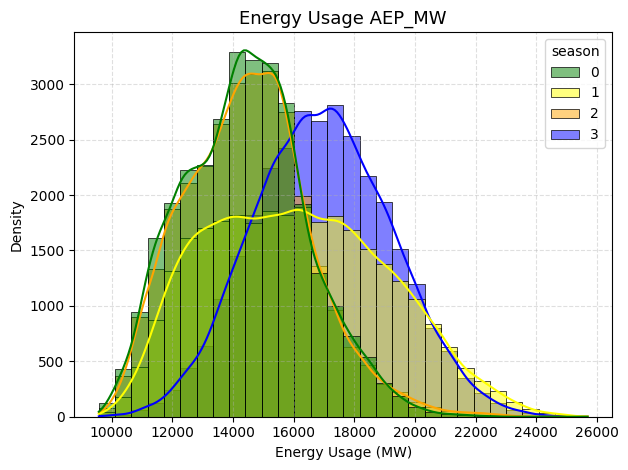

In [15]:
sns.histplot(df_aep[['AEP_MW', 'year', 'season']], 
             x='AEP_MW',
             kde=True,
             bins=30,
             hue='season',
             palette=['green', 'yellow', 'orange', 'blue'],
             alpha=0.5,
             linewidth=0.5)

plt.title('Energy Usage AEP_MW', fontsize=13)
plt.xlabel('Energy Usage (MW)')
plt.ylabel('Density')
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

(Brief Analysis based on the report)

### Seasonal Component Analysis

Now we need to understand and isolate seasonality of this time series by performing a decomposition using the seasonal_decompose function. This splits the time series into four components: Observed, representing the original data; Trend, showing long-term movement; Seasonal, highlighting recurring patterns over a fixed period (e.g., yearly); and Residual, capturing the noise or irregular fluctuations. The decomposition helps analyze how these components contribute to the overall behavior of the time series, aiding in better modeling and forecasting.Now we need to understand and isolate seasonality of this time series (explain it better)

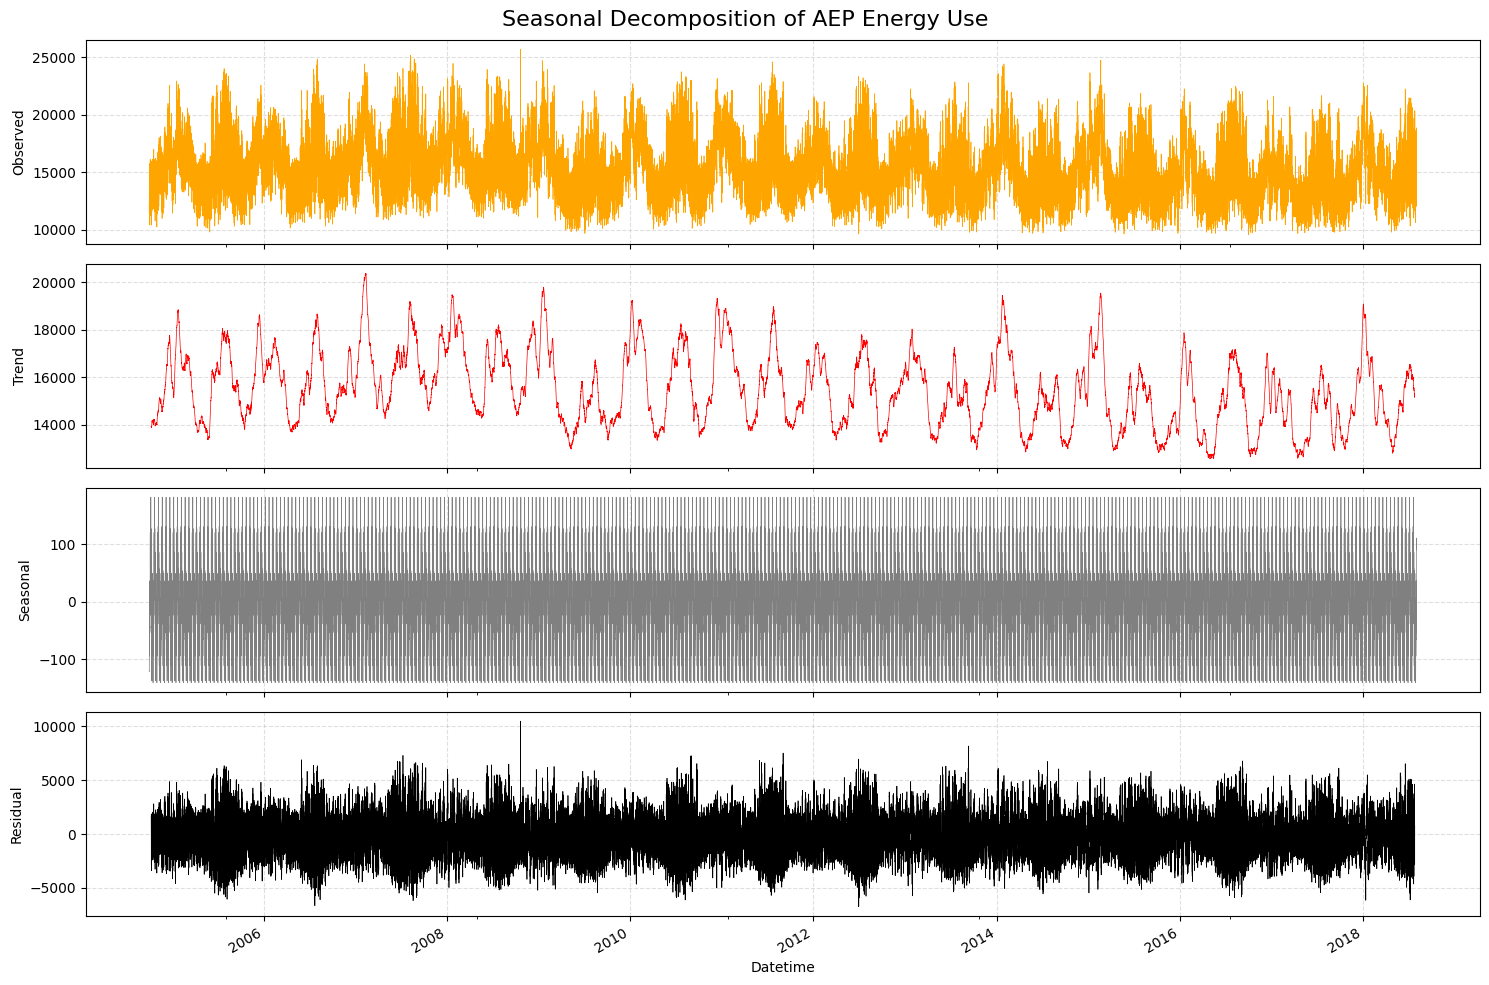

In [16]:
# Datatime Decomposition
result = seasonal_decompose(df_aep['AEP_MW'], period=365)

fig, axes = plt.subplots(4, 1, figsize=(15, 10), sharex=True)

# Observed part
result.observed.plot(ax=axes[0], color='orange', linewidth=0.5)
axes[0].set_ylabel('Observed')
axes[0].grid(True, linestyle='--', alpha=0.4)

# Trend part
result.trend.plot(ax=axes[1], color='red', linewidth=0.5)
axes[1].set_ylabel('Trend')
axes[1].grid(True, linestyle='--', alpha=0.4)

# Seasonal part
result.seasonal.plot(ax=axes[2], color='grey', linewidth=0.5)
axes[2].set_ylabel('Seasonal')
axes[2].grid(True, linestyle='--', alpha=0.4)

# Residual part
result.resid.plot(ax=axes[3], color='black', linewidth=0.5)
axes[3].set_ylabel('Residual')
axes[3].grid(True, linestyle='--', alpha=0.4)

plt.suptitle('Seasonal Decomposition of AEP Energy Use', fontsize=16)
plt.xlabel('Datetime')
plt.tight_layout()
plt.show()

Remove the Trend: Apply a first differencing (d=1) to eliminate the trend.

In [17]:
# Apply first differencing to remove the trend
df_aep['AEP_MW_differenced'] = df_aep['AEP_MW'].diff()

# Drop the first row since it will have a NaN value after differencing
df_aep = df_aep.dropna(subset=['AEP_MW_differenced'])

df_aep

,AEP_MW,hour,day,month,year,season,AEP_MW_differenced
Datetime,,,,,,,
2004-10-01 02:00:00,11935.0,2,4,10,2004,2,-444.0
2004-10-01 03:00:00,11692.0,3,4,10,2004,2,-243.0
2004-10-01 04:00:00,11597.0,4,4,10,2004,2,-95.0
2004-10-01 05:00:00,11681.0,5,4,10,2004,2,84.0
2004-10-01 06:00:00,12280.0,6,4,10,2004,2,599.0
...,...,...,...,...,...,...,...
2018-08-02 20:00:00,17673.0,20,3,8,2018,1,-445.0
2018-08-02 21:00:00,17303.0,21,3,8,2018,1,-370.0
2018-08-02 22:00:00,17001.0,22,3,8,2018,1,-302.0


Handle Seasonality: If your data is seasonal (e.g., annual cycles), apply seasonal differencing (D=1) with the seasonal period (m) determined from the data. The period could be 12 (for monthly seasonality) or 24 (for daily seasonality in hourly data).

In [18]:
pd.options.mode.chained_assignment = None  # Suppress warnings

# Seasonal period (e.g., daily seasonality for hourly data)
m = 24

# Apply seasonal differencing using .loc[] to avoid the warning
df_aep.loc[:, 'AEP_MW_seasonal_diff'] = df_aep['AEP_MW_differenced'] - df_aep['AEP_MW_differenced'].shift(m)

# Drop rows with NaN values after seasonal differencing
df_aep = df_aep.dropna(subset=['AEP_MW_seasonal_diff'])

df_aep

,AEP_MW,hour,day,month,year,season,AEP_MW_differenced,AEP_MW_seasonal_diff
Datetime,,,,,,,,
2004-10-02 02:00:00,11672.0,2,5,10,2004,2,-588.0,-144.0
2004-10-02 03:00:00,11352.0,3,5,10,2004,2,-320.0,-77.0
2004-10-02 04:00:00,11177.0,4,5,10,2004,2,-175.0,-80.0
2004-10-02 05:00:00,11142.0,5,5,10,2004,2,-35.0,-119.0
2004-10-02 06:00:00,11331.0,6,5,10,2004,2,189.0,-410.0
...,...,...,...,...,...,...,...,...
2018-08-02 20:00:00,17673.0,20,3,8,2018,1,-445.0,-154.0
2018-08-02 21:00:00,17303.0,21,3,8,2018,1,-370.0,-248.0
2018-08-02 22:00:00,17001.0,22,3,8,2018,1,-302.0,-42.0


Check for stationarity

In [19]:
pd.options.mode.chained_assignment = None  # Suppress warnings

# Function to perform ADF test
def adf_test(series):
    result = adfuller(series, autolag='AIC')
    print(f"ADF Statistic: {result[0]}")
    print(f"p-value: {result[1]}")
    print("Critical Values:")
    for key, value in result[4].items():
        print(f"   {key}: {value}")
    if result[1] <= 0.05:
        print("Reject the null hypothesis (Stationary)")
    else:
        print("Fail to reject the null hypothesis (Non-stationary)")

# Perform the test on the seasonal differenced column
adf_test(df_aep['AEP_MW_seasonal_diff'])

# Function to perform KPSS test
def kpss_test(series):
    result = kpss(series, regression='c')
    print(f"KPSS Statistic: {result[0]}")
    print(f"p-value: {result[1]}")
    print("Critical Values:")
    for key, value in result[3].items():
        print(f"   {key}: {value}")
    if result[1] <= 0.05:
        print("Reject the null hypothesis (Non-stationary)")
    else:
        print("Fail to reject the null hypothesis (Stationary)")

# Perform the test on the seasonal differenced column
kpss_test(df_aep['AEP_MW_seasonal_diff'])


ADF Statistic: -74.64168760652547
p-value: 0.0
Critical Values:
   1%: -3.430403966449884
   5%: -2.861563852371292
   10%: -2.5667826957745854
Reject the null hypothesis (Stationary)
KPSS Statistic: 0.00017367140100224885
p-value: 0.1
Critical Values:
   10%: 0.347
   5%: 0.463
   2.5%: 0.574
   1%: 0.739
Fail to reject the null hypothesis (Stationary)


/tmp/ipykernel_9030/4149372682.py:21: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  result = kpss(series, regression='c')


### ACF and PACF

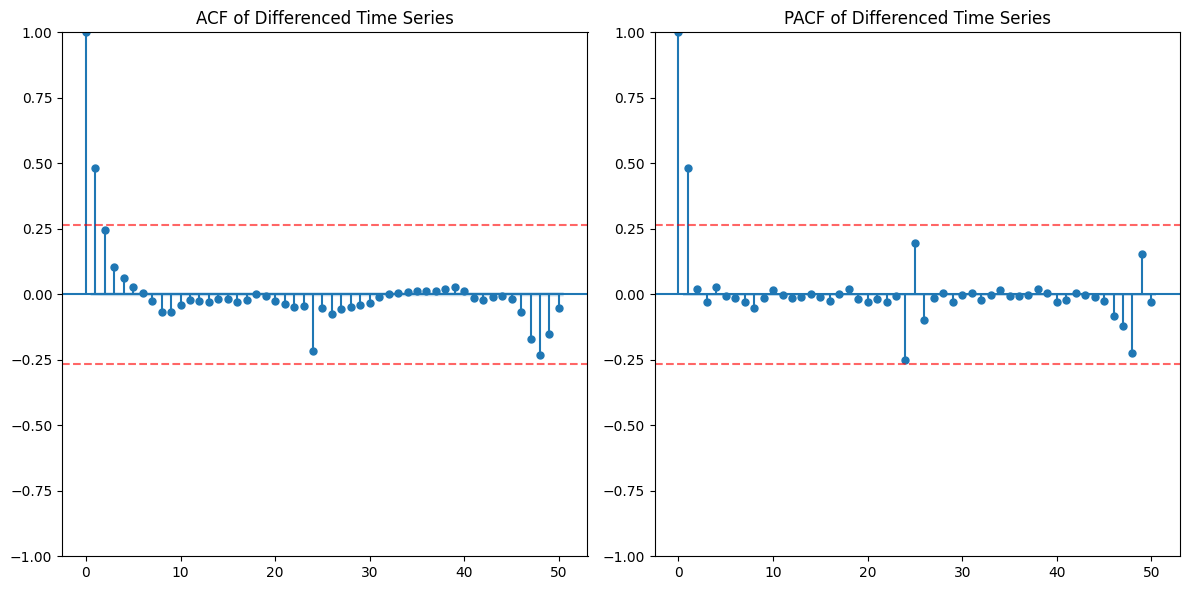

In [20]:
# n for these two graphs
n = 55

# Calculate the threshold for ACF and PACF: +/- 1.96 / sqrt(n)
conf_interval = 1.96 / np.sqrt(n)

# Assuming df_aep['AEP_MW_seasonal_diff'] is the modified time series after differencing
plt.figure(figsize=(12, 6))

# ACF plot
plt.subplot(121)
plot_acf(df_aep['AEP_MW_seasonal_diff'].dropna(), lags=50, ax=plt.gca())
plt.title('ACF of Differenced Time Series')

# Manually add the confidence interval to ACF plot
plt.gca().axhline(y=conf_interval, color='r', linestyle='--', alpha=0.6)  # Upper threshold
plt.gca().axhline(y=-conf_interval, color='r', linestyle='--', alpha=0.6)  # Lower threshold

# PACF plot
plt.subplot(122)
plot_pacf(df_aep['AEP_MW_seasonal_diff'].dropna(), lags=50, ax=plt.gca())
plt.title('PACF of Differenced Time Series')

# Manually add the confidence interval to PACF plot
plt.gca().axhline(y=conf_interval, color='r', linestyle='--', alpha=0.6)  # Upper threshold
plt.gca().axhline(y=-conf_interval, color='r', linestyle='--', alpha=0.6)  # Lower threshold

plt.tight_layout()
plt.show()

## 3. Training & Test Dataset
We split the data into training and test datasets for ARIMA modeling to evaluate the model's ability to generalize and make accurate predictions on unseen data. The training set is used to fit the ARIMA model, while the test set helps assess its forecasting performance and ensure it doesn't overfit.

- **Training dataset**: values before 2016
- **Test dataset**: values after 2016

(After modifying the Time Series, use the same code, but with the modified Time Series)

In [21]:
# Train Test Split
df_train, df_test = df_aep[df_aep.index < '2016-01-01'], df_aep[df_aep.index >= '2016-01-01']

# Calculate percentages
train_size = len(df_train)
test_size = len(df_test)
total_size = train_size + test_size
train_per = (train_size / total_size) * 100
test_per = (test_size / total_size) * 100

print('TRAINING & TEST DATASET\n')
print('Train dataset:', len(df_train), f'({train_per:.2f}%)')
print('Test dataset:', len(df_test), f'({test_per:.2f}%)')

TRAINING & TEST DATASET

Train dataset: 98568 (81.29%)
Test dataset: 22680 (18.71%)


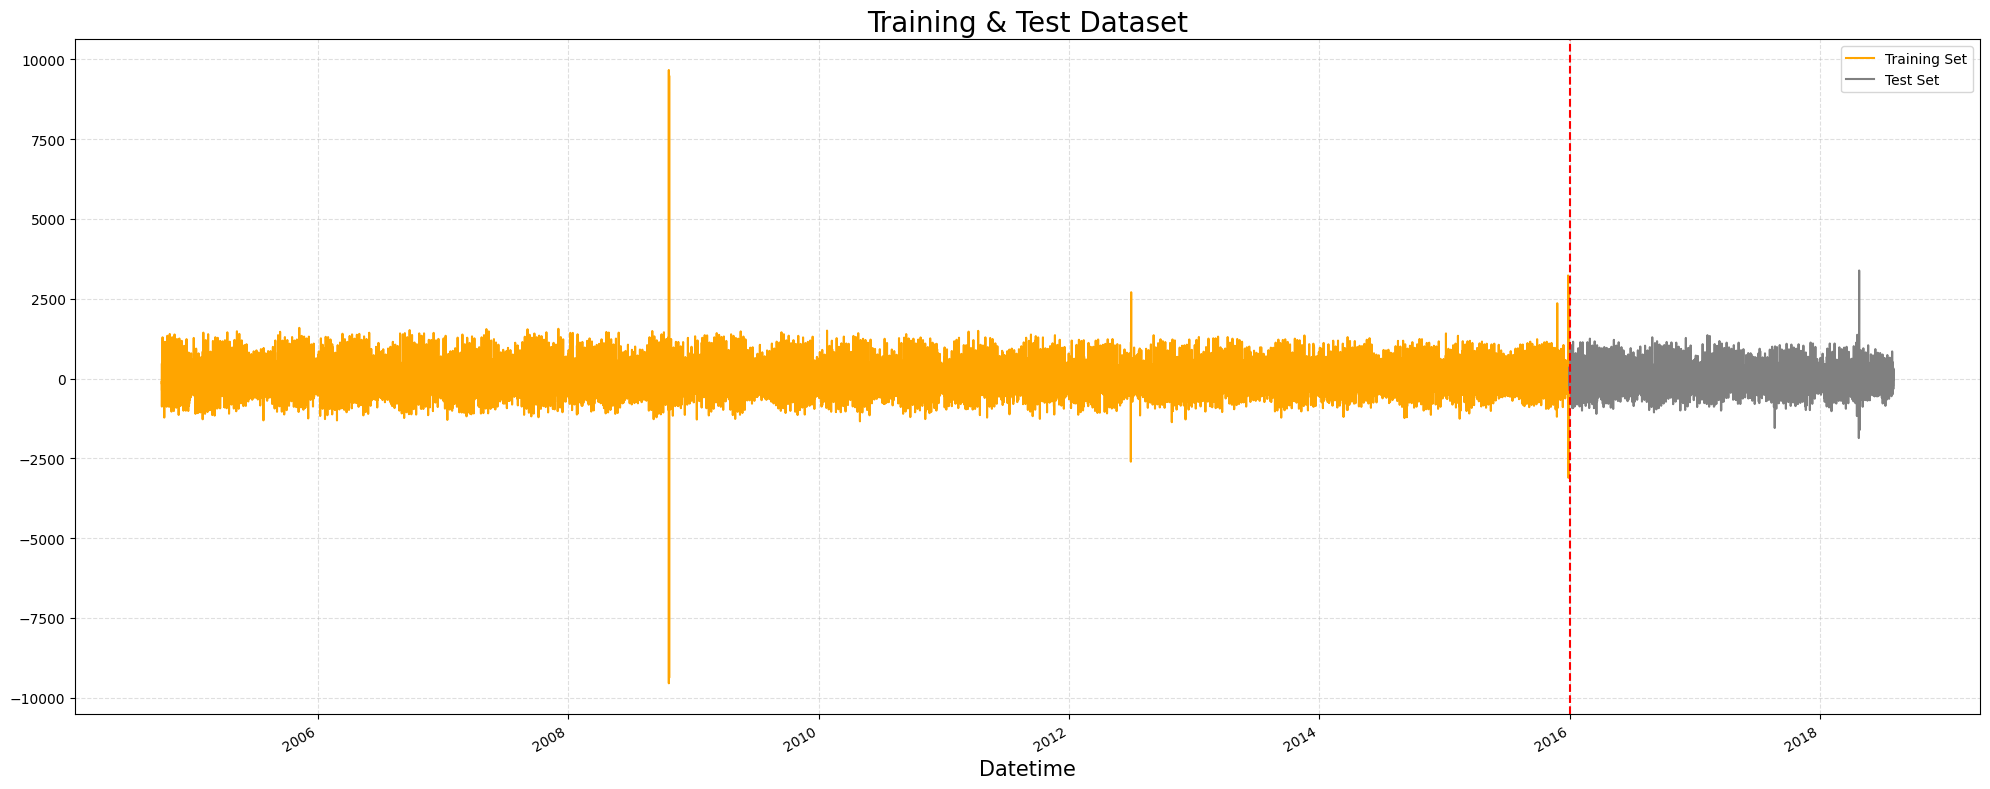

In [22]:
# Display diagram with train/test data
plt.figure(figsize=(20,8))

df_train['AEP_MW_seasonal_diff'].plot(label='Training Set', color = 'orange')
df_test['AEP_MW_seasonal_diff'].plot(label='Test Set', color = 'grey')
plt.axvline('2016-01-01', color='red', ls='--', lw=1.5)
plt.title('Training & Test Dataset', fontsize=20)
plt.xlabel('Datetime', fontsize = 15)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

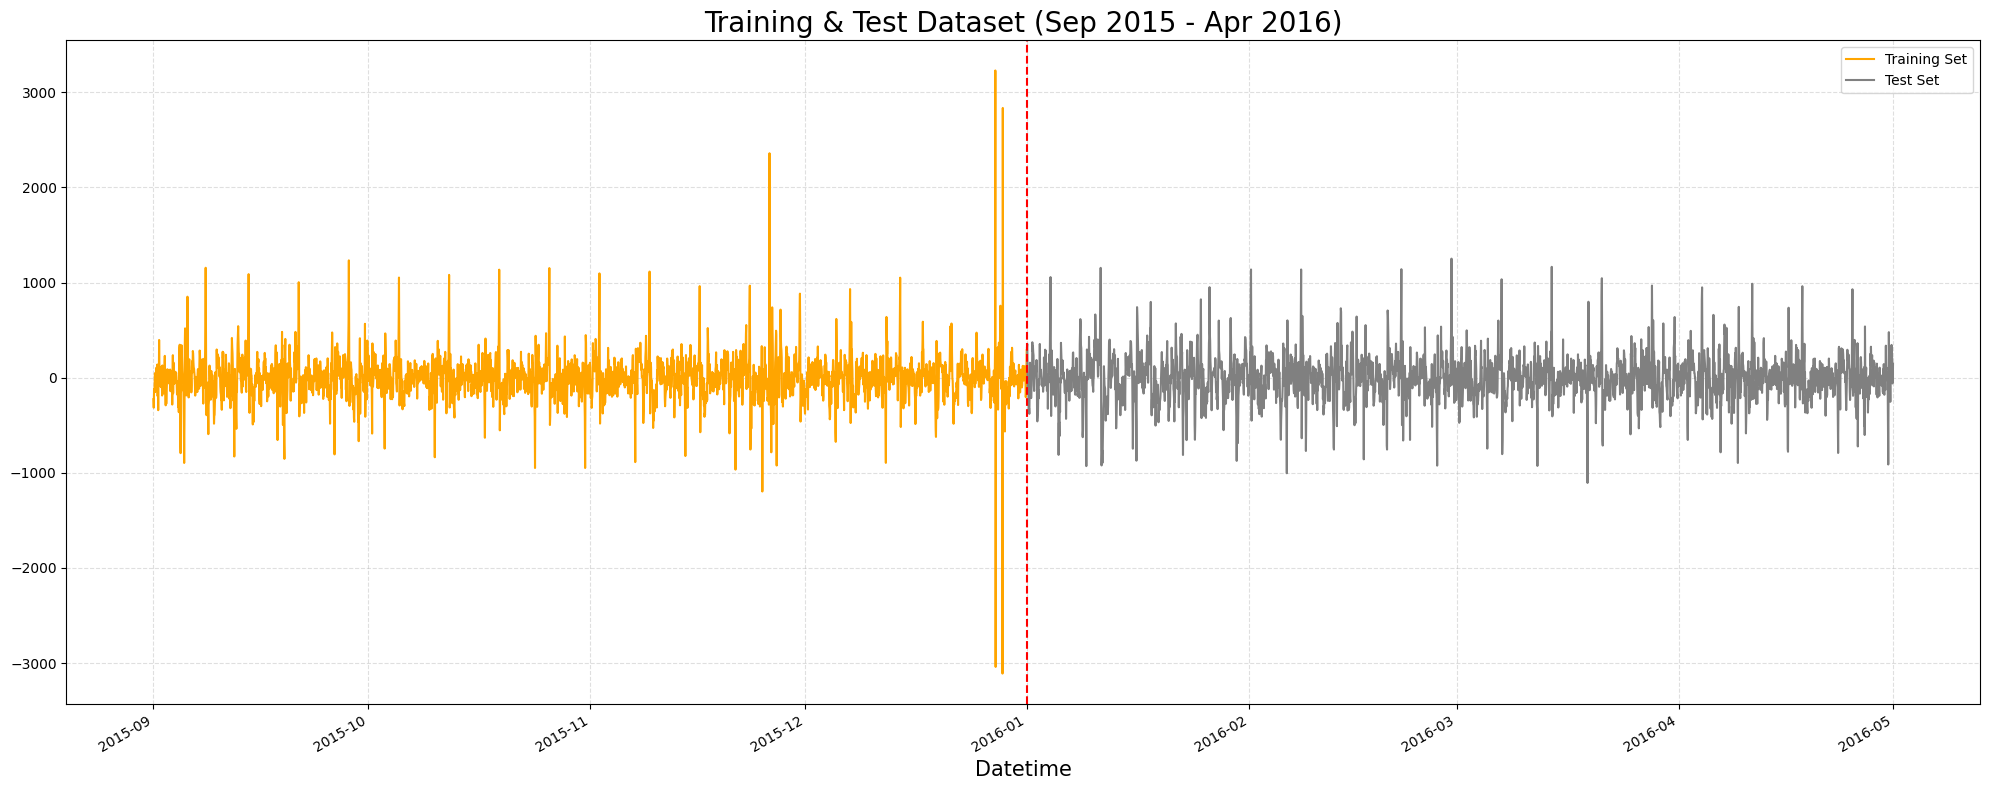

In [23]:
# Plot the filtered data for the specified range
plt.figure(figsize=(20, 8))

df_train.loc['2015-09':'2016-04', 'AEP_MW_seasonal_diff'].plot(label='Training Set', color='orange')
df_test.loc['2015-09':'2016-04', 'AEP_MW_seasonal_diff'].plot(label='Test Set', color='grey')
plt.axvline('2016-01-01', color='red', ls='--', lw=1.5)
plt.title('Training & Test Dataset (Sep 2015 - Apr 2016)', fontsize=20)
plt.xlabel('Datetime', fontsize=15)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

# ARIMA (SARIMA) Implementation

Performing stepwise search to minimize aic
 ARIMA(2,0,2)(1,0,1)[12] intercept   : AIC=51712.061, Time=6.60 sec
 ARIMA(0,0,0)(0,0,0)[12] intercept   : AIC=52906.945, Time=0.04 sec
 ARIMA(1,0,0)(1,0,0)[12] intercept   : AIC=52282.940, Time=0.77 sec
 ARIMA(0,0,1)(0,0,1)[12] intercept   : AIC=51826.529, Time=2.00 sec
 ARIMA(0,0,0)(0,0,0)[12]             : AIC=52905.232, Time=0.04 sec
 ARIMA(2,0,2)(0,0,1)[12] intercept   : AIC=51710.081, Time=4.38 sec
 ARIMA(2,0,2)(0,0,0)[12] intercept   : AIC=51722.136, Time=1.06 sec
 ARIMA(2,0,2)(0,0,2)[12] intercept   : AIC=51712.022, Time=12.50 sec
 ARIMA(2,0,2)(1,0,0)[12] intercept   : AIC=51710.030, Time=4.27 sec
 ARIMA(2,0,2)(2,0,0)[12] intercept   : AIC=51712.031, Time=11.44 sec
 ARIMA(2,0,2)(2,0,1)[12] intercept   : AIC=inf, Time=14.40 sec
 ARIMA(1,0,2)(1,0,0)[12] intercept   : AIC=51706.246, Time=4.53 sec
 ARIMA(1,0,2)(0,0,0)[12] intercept   : AIC=51720.137, Time=1.18 sec
 ARIMA(1,0,2)(2,0,0)[12] intercept   : AIC=51708.246, Time=11.45 sec
 ARIMA(

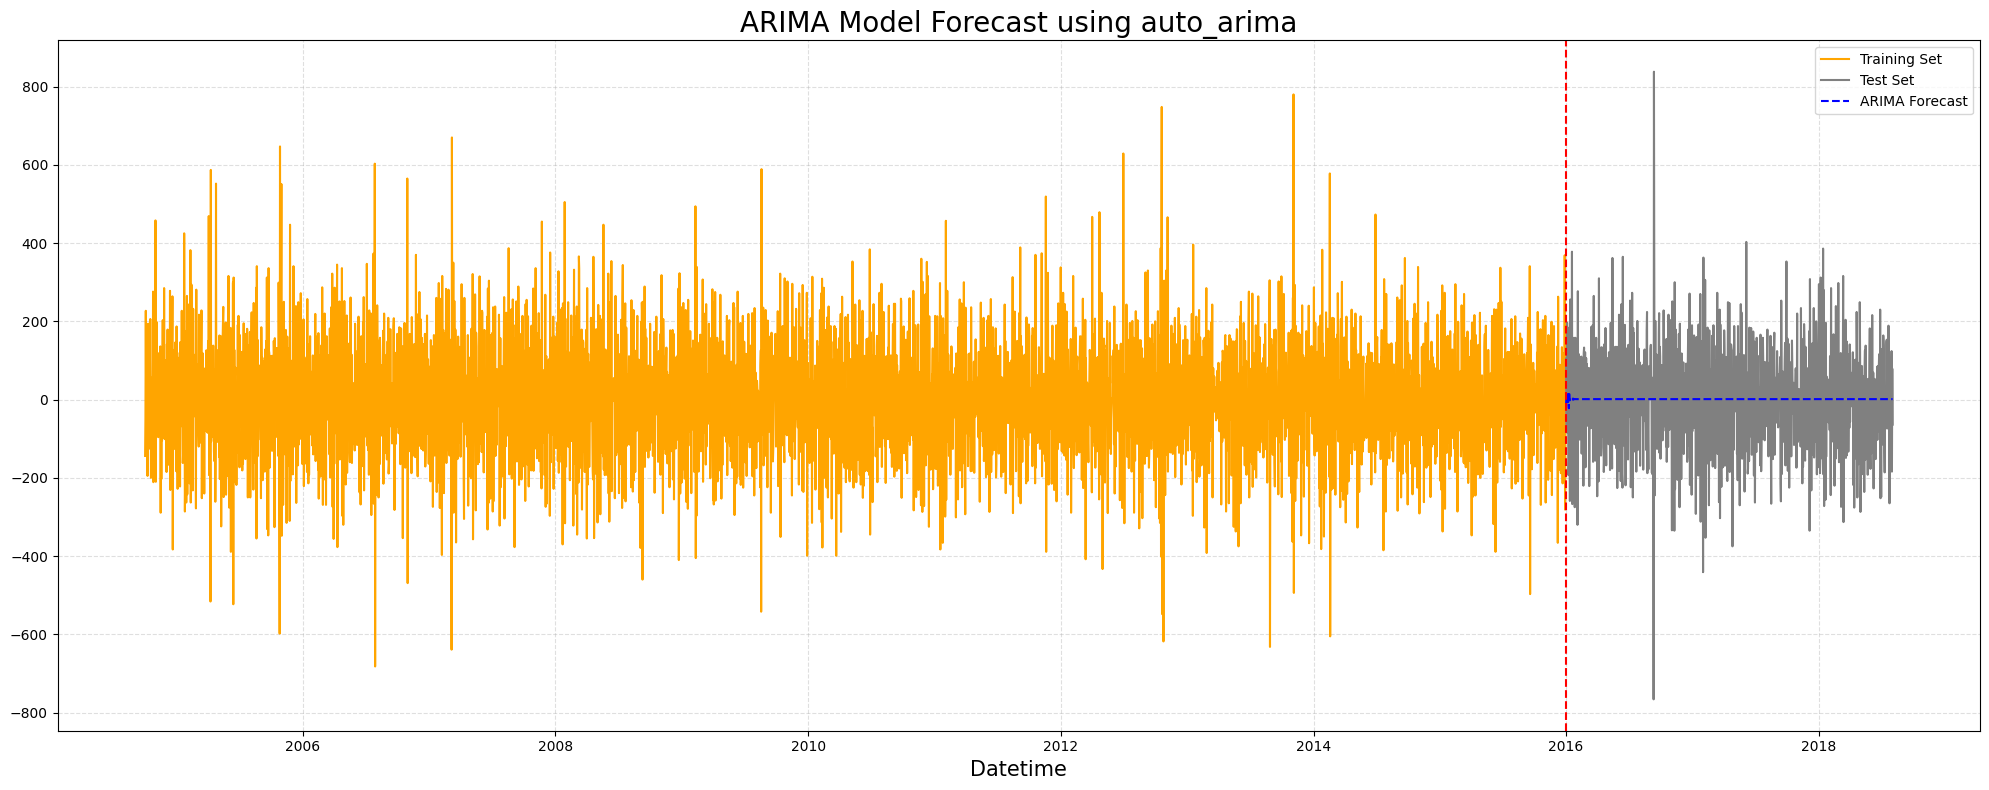

In [46]:
# Fit ARIMA model using auto_arima
df_train['AEP_MW_seasonal_diff'] = df_train['AEP_MW_seasonal_diff'].fillna(method='ffill')
model = pm.auto_arima(df_train['AEP_MW_seasonal_diff'], seasonal=True, m=12, stepwise=True, trace=True)

# Show the summary of the best model
print(model.summary())

# Forecast the future values
forecast = model.predict(n_periods=len(df_test))

# Plot the predictions along with the actual values
plt.figure(figsize=(20, 8))
plt.plot(df_train['AEP_MW_seasonal_diff'], label='Training Set', color='orange')
plt.plot(df_test['AEP_MW_seasonal_diff'], label='Test Set', color='grey')
plt.plot(df_test.index, forecast, label='ARIMA Forecast', color='blue', linestyle='--')
plt.axvline(pd.to_datetime('2016-01-01'), color='red', ls='--', lw=1.5)  # Convert to datetime
plt.title('ARIMA Model Forecast using auto_arima', fontsize=20)
plt.xlabel('Datetime', fontsize=15)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

In [47]:
# Performing stepwise search to minimize aic
#  ARIMA(2,0,2)(1,0,1)[12] intercept   : AIC=51712.061, Time=6.99 sec
#  ARIMA(0,0,0)(0,0,0)[12] intercept   : AIC=52906.945, Time=0.05 sec
#  ARIMA(1,0,0)(1,0,0)[12] intercept   : AIC=52282.940, Time=0.57 sec
#  ARIMA(0,0,1)(0,0,1)[12] intercept   : AIC=51826.529, Time=1.90 sec
#  ARIMA(0,0,0)(0,0,0)[12]             : AIC=52905.232, Time=0.04 sec
#  ARIMA(2,0,2)(0,0,1)[12] intercept   : AIC=51710.081, Time=3.90 sec
#  ARIMA(2,0,2)(0,0,0)[12] intercept   : AIC=51722.136, Time=1.06 sec
#  ARIMA(2,0,2)(0,0,2)[12] intercept   : AIC=51712.022, Time=11.85 sec
#  ARIMA(2,0,2)(1,0,0)[12] intercept   : AIC=51710.030, Time=3.59 sec
#  ARIMA(2,0,2)(2,0,0)[12] intercept   : AIC=51712.031, Time=10.43 sec
#  ARIMA(2,0,2)(2,0,1)[12] intercept   : AIC=inf, Time=11.17 sec
#  ARIMA(1,0,2)(1,0,0)[12] intercept   : AIC=51706.246, Time=3.96 sec
#  ARIMA(1,0,2)(0,0,0)[12] intercept   : AIC=51720.137, Time=1.07 sec
#  ARIMA(1,0,2)(2,0,0)[12] intercept   : AIC=51708.246, Time=10.26 sec
#  ARIMA(1,0,2)(1,0,1)[12] intercept   : AIC=51708.370, Time=5.20 sec
#  ARIMA(1,0,2)(0,0,1)[12] intercept   : AIC=51706.321, Time=4.28 sec
#  ARIMA(1,0,2)(2,0,1)[12] intercept   : AIC=inf, Time=11.87 sec
#  ARIMA(0,0,2)(1,0,0)[12] intercept   : AIC=51722.394, Time=2.17 sec
#  ARIMA(1,0,1)(1,0,0)[12] intercept   : AIC=51706.725, Time=2.03 sec
#  ARIMA(1,0,3)(1,0,0)[12] intercept   : AIC=51707.791, Time=4.49 sec
#  ARIMA(0,0,1)(1,0,0)[12] intercept   : AIC=51827.468, Time=1.36 sec
#  ARIMA(0,0,3)(1,0,0)[12] intercept   : AIC=51708.576, Time=2.66 sec
#  ARIMA(2,0,1)(1,0,0)[12] intercept   : AIC=51706.024, Time=3.06 sec
#  ARIMA(2,0,1)(0,0,0)[12] intercept   : AIC=51720.205, Time=0.77 sec
#  ARIMA(2,0,1)(2,0,0)[12] intercept   : AIC=51708.024, Time=8.16 sec
#  ARIMA(2,0,1)(1,0,1)[12] intercept   : AIC=51708.023, Time=4.80 sec
#  ARIMA(2,0,1)(0,0,1)[12] intercept   : AIC=51706.118, Time=3.14 sec
#  ARIMA(2,0,1)(2,0,1)[12] intercept   : AIC=inf, Time=11.84 sec
#  ARIMA(2,0,0)(1,0,0)[12] intercept   : AIC=52062.240, Time=0.68 sec
#  ARIMA(3,0,1)(1,0,0)[12] intercept   : AIC=51707.956, Time=3.98 sec
#  ARIMA(3,0,0)(1,0,0)[12] intercept   : AIC=51960.693, Time=0.83 sec
#  ARIMA(3,0,2)(1,0,0)[12] intercept   : AIC=51706.475, Time=5.15 sec
#  ARIMA(2,0,1)(1,0,0)[12]             : AIC=51711.013, Time=1.25 sec

# Best model:  ARIMA(2,0,1)(1,0,0)[12] intercept
# Total fit time: 144.689 seconds
#                                       SARIMAX Results                                      
# ===========================================================================================
# Dep. Variable:                                   y   No. Observations:                 4108
# Model:             SARIMAX(2, 0, 1)x(1, 0, [], 12)   Log Likelihood              -25847.012
# Date:                             Wed, 01 Jan 2025   AIC                          51706.024
# Time:                                     21:53:40   BIC                          51743.949
# Sample:                                 10-02-2004   HQIC                         51719.449
#                                       - 12-31-2015                                         
# Covariance Type:                               opg                                         
# ==============================================================================
#                  coef    std err          z      P>|z|      [0.025      0.975]
# ------------------------------------------------------------------------------
# intercept      0.9642      0.367      2.627      0.009       0.245       1.684
# ar.L1          0.2569      0.020     12.545      0.000       0.217       0.297
# ar.L2          0.0305      0.019      1.624      0.104      -0.006       0.067
# ma.L1         -0.8230      0.016    -52.821      0.000      -0.854      -0.792
# ar.S.L12      -0.0634      0.016     -4.021      0.000      -0.094      -0.033
# sigma2      1.708e+04    285.840     59.755      0.000    1.65e+04    1.76e+04
# ===================================================================================
# Ljung-Box (L1) (Q):                   0.00   Jarque-Bera (JB):               482.95
# Prob(Q):                              1.00   Prob(JB):                         0.00
# Heteroskedasticity (H):               0.91   Skew:                             0.22
# Prob(H) (two-sided):                  0.07   Kurtosis:                         4.62
# ===================================================================================

# Warnings:
# [1] Covariance matrix calculated using the outer product of gradients (complex-step).

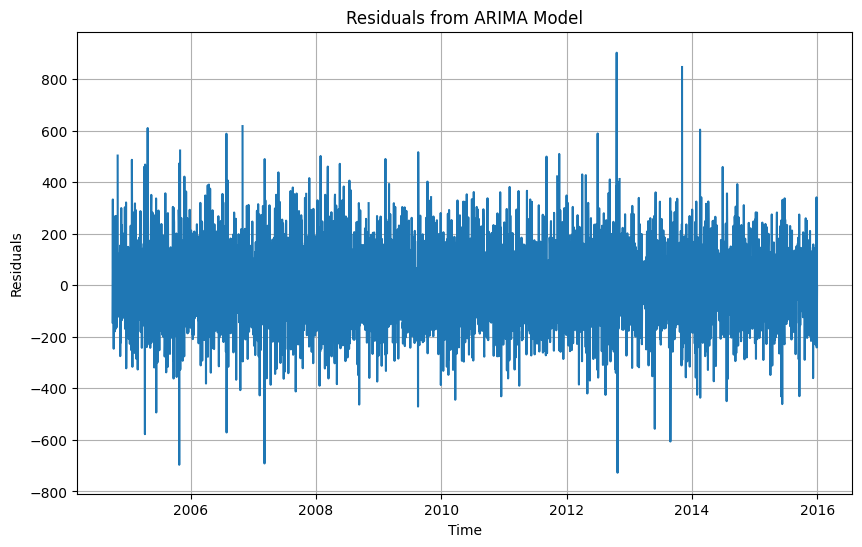

       lb_stat      lb_pvalue
10  749.106662  1.786689e-154


In [49]:
# Calculate residuals
residuals = model_fit.resid

# Plot residuals
plt.figure(figsize=(10, 6))
plt.plot(residuals)
plt.title('Residuals from ARIMA Model')
plt.xlabel('Time')
plt.ylabel('Residuals')
plt.grid(True)
plt.show()

# Ljung-Box Test
residuals = residuals.dropna()
lb_test = acorr_ljungbox(residuals, lags=[10], return_df=True)
print(lb_test)

# You can interpret the Ljung-Box p-value:
# If p-value > 0.05, residuals are independent (no autocorrelation)
# If p-value < 0.05, residuals have autocorrelation, suggesting model improvement is needed

In [50]:
print(len(residuals))

4098


In [51]:
print(residuals.describe())

count    4098.000000
mean        0.358885
std       157.823766
min      -727.271055
25%      -103.841382
50%        -3.477775
75%        98.885326
max       901.702539
dtype: float64


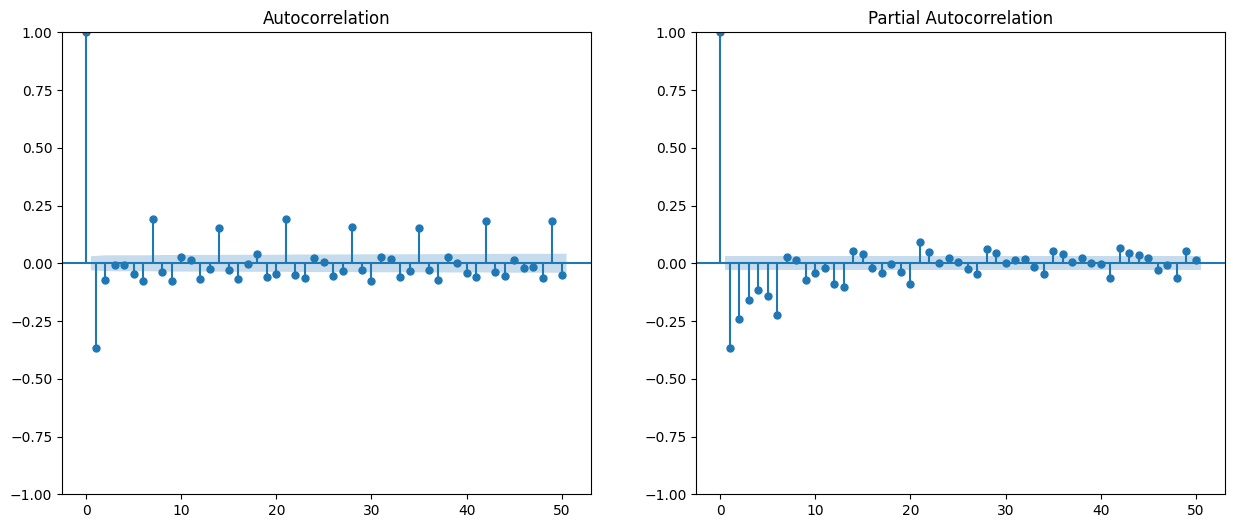

In [52]:
# Plot ACF and PACF
plt.figure(figsize=(15, 6))
plt.subplot(121)
plot_acf(df_train['AEP_MW_seasonal_diff'], lags=50, ax=plt.gca())
plt.subplot(122)
plot_pacf(df_train['AEP_MW_seasonal_diff'], lags=50, ax=plt.gca())
plt.show()

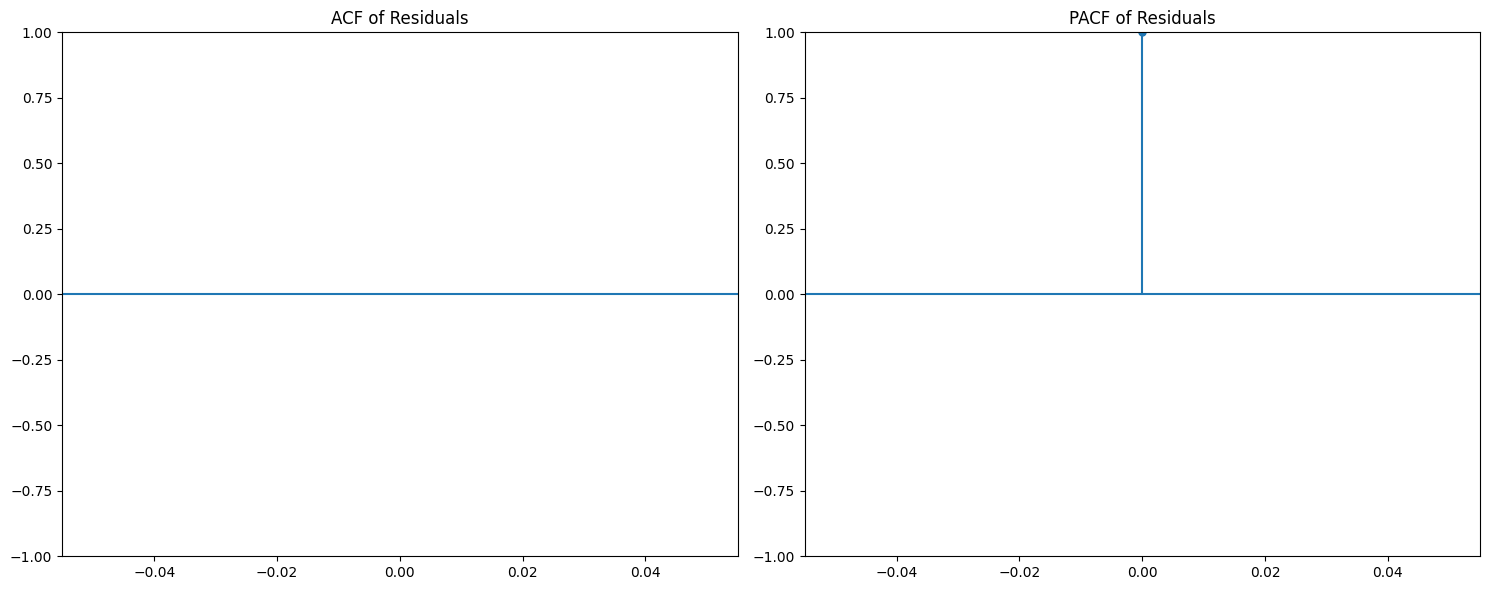

In [53]:
# Get residuals from the fitted ARIMA model
residuals = model_fit.resid

# Plot ACF and PACF of residuals
plt.figure(figsize=(15, 6))

# ACF plot
plt.subplot(121)
plot_acf(residuals, lags=50, ax=plt.gca())
plt.title('ACF of Residuals')

# PACF plot
plt.subplot(122)
plot_pacf(residuals, lags=50, ax=plt.gca())
plt.title('PACF of Residuals')

plt.tight_layout()
plt.show()

/home/bern/.local/lib/python3.10/site-packages/statsmodels/tsa/statespace/sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
/home/bern/.local/lib/python3.10/site-packages/statsmodels/tsa/statespace/sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'


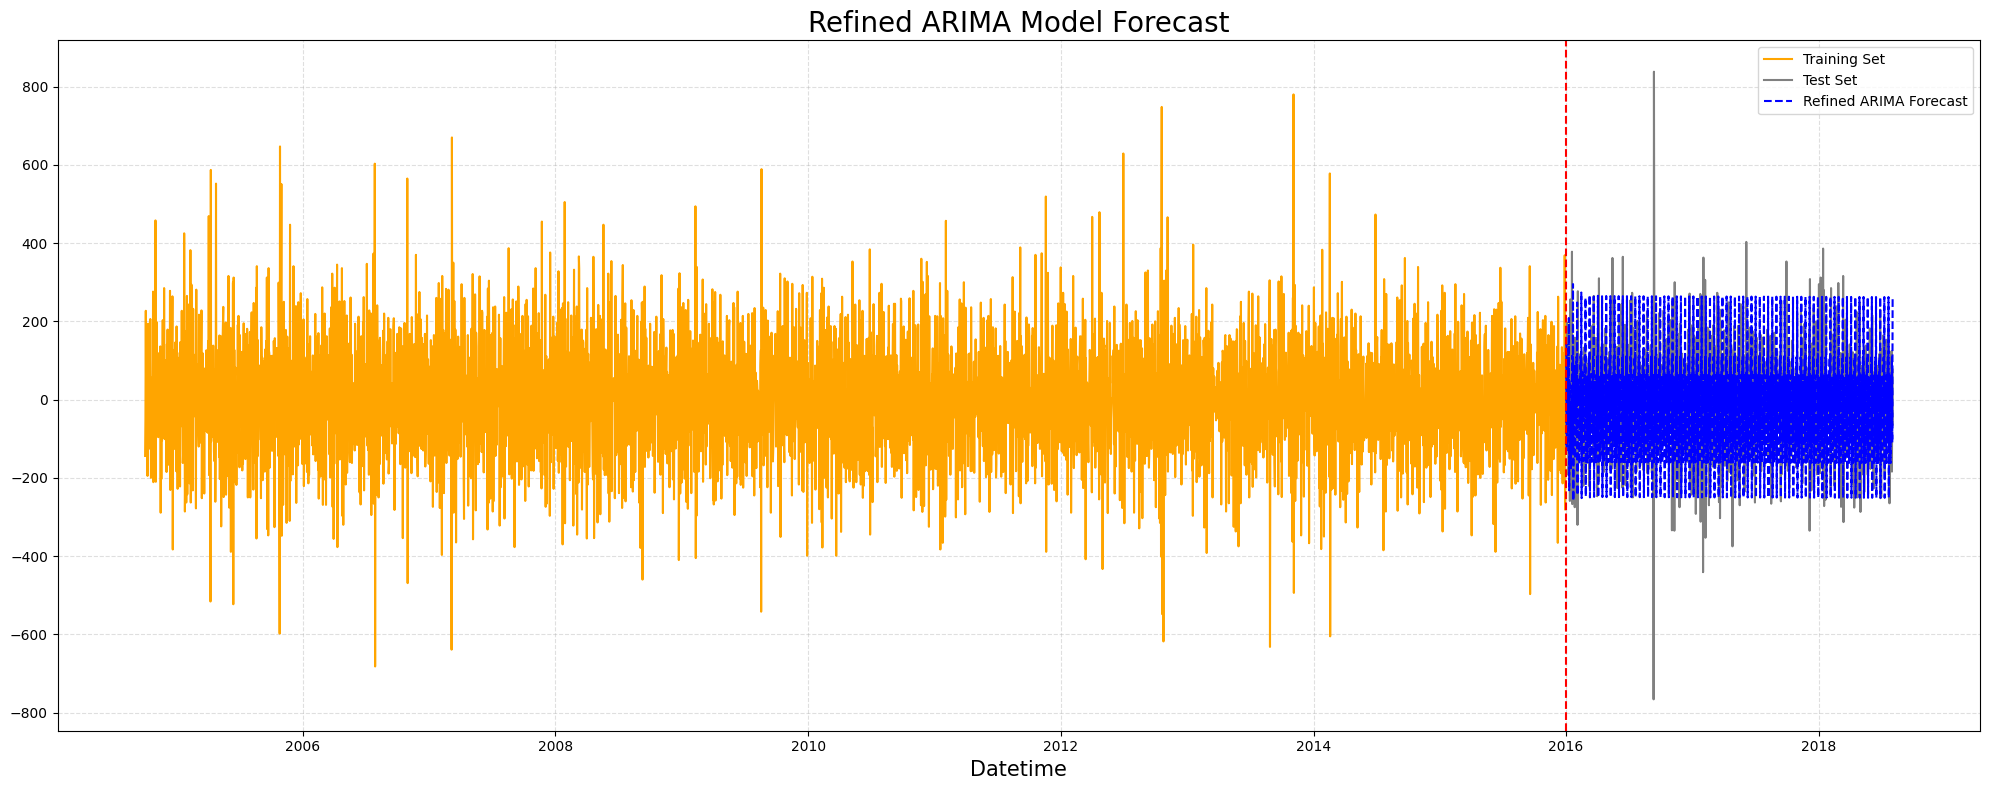

In [54]:
# Manually specify different parameters based on auto_arima results
model_refined = ARIMA(df_train['AEP_MW_seasonal_diff'], order=(5, 1, 2), seasonal_order=(1, 1, 0, 12))
model_refined_fit = model_refined.fit()

# Forecast the future values
forecast_refined = model_refined_fit.forecast(steps=len(df_test))

# Plot the predictions along with the actual values
plt.figure(figsize=(20, 8))
plt.plot(df_train['AEP_MW_seasonal_diff'], label='Training Set', color='orange')
plt.plot(df_test['AEP_MW_seasonal_diff'], label='Test Set', color='grey')
plt.plot(df_test.index, forecast_refined, label='Refined ARIMA Forecast', color='blue', linestyle='--')
plt.axvline(pd.to_datetime('2016-01-01'), color='red', ls='--', lw=1.5)
plt.title('Refined ARIMA Model Forecast', fontsize=20)
plt.xlabel('Datetime', fontsize=15)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()


In [66]:
# Calculate residuals
residuals = model_refined_fit.resid

# Ljung-Box Test
residuals = residuals.dropna()
lb_test = acorr_ljungbox(residuals, lags=[10], return_df=True)
print(lb_test)

       lb_stat     lb_pvalue
10  399.824375  1.025933e-79


                                     SARIMAX Results                                      
Dep. Variable:               AEP_MW_seasonal_diff   No. Observations:                 4108
Model:             SARIMAX(3, 0, 1)x(1, 0, 1, 12)   Log Likelihood              -25758.456
Date:                            Wed, 01 Jan 2025   AIC                          51530.911
Time:                                    22:28:04   BIC                          51575.131
Sample:                                10-02-2004   HQIC                         51546.568
                                     - 12-31-2015                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.2513      0.024     10.569      0.000       0.205       0.298
ar.L2          0.0297      0.019   

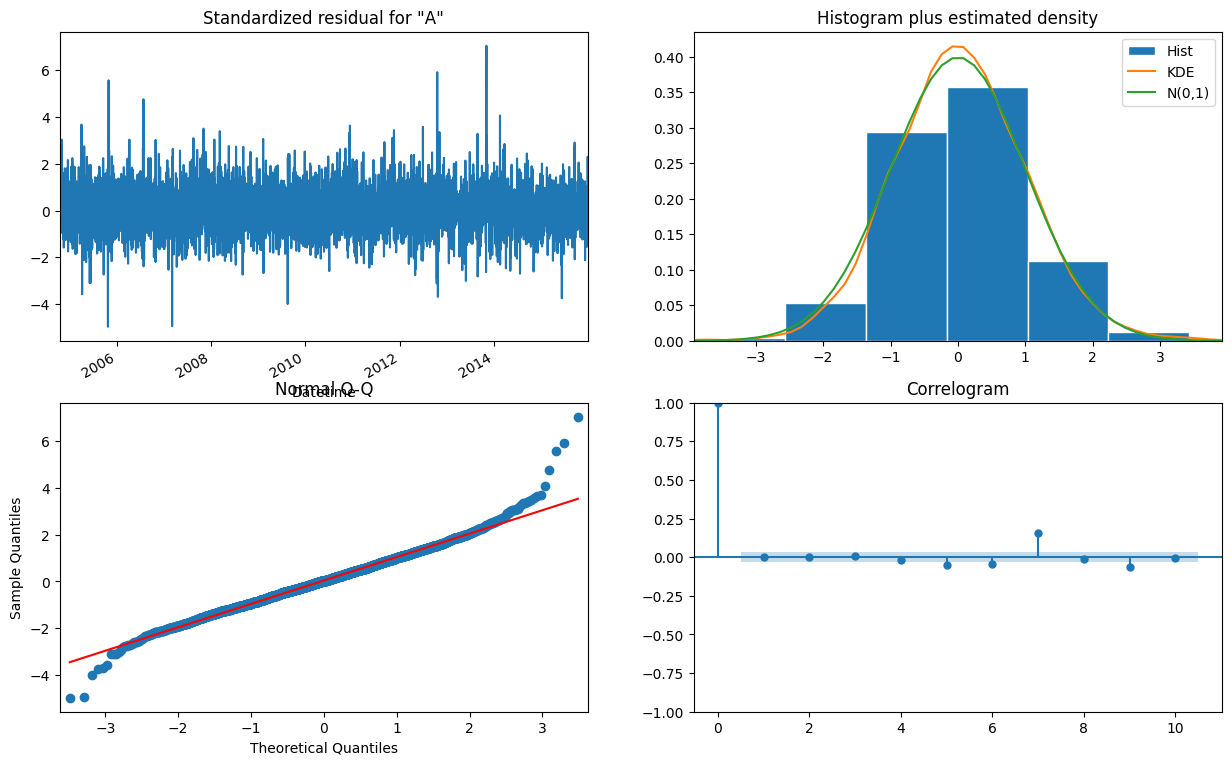

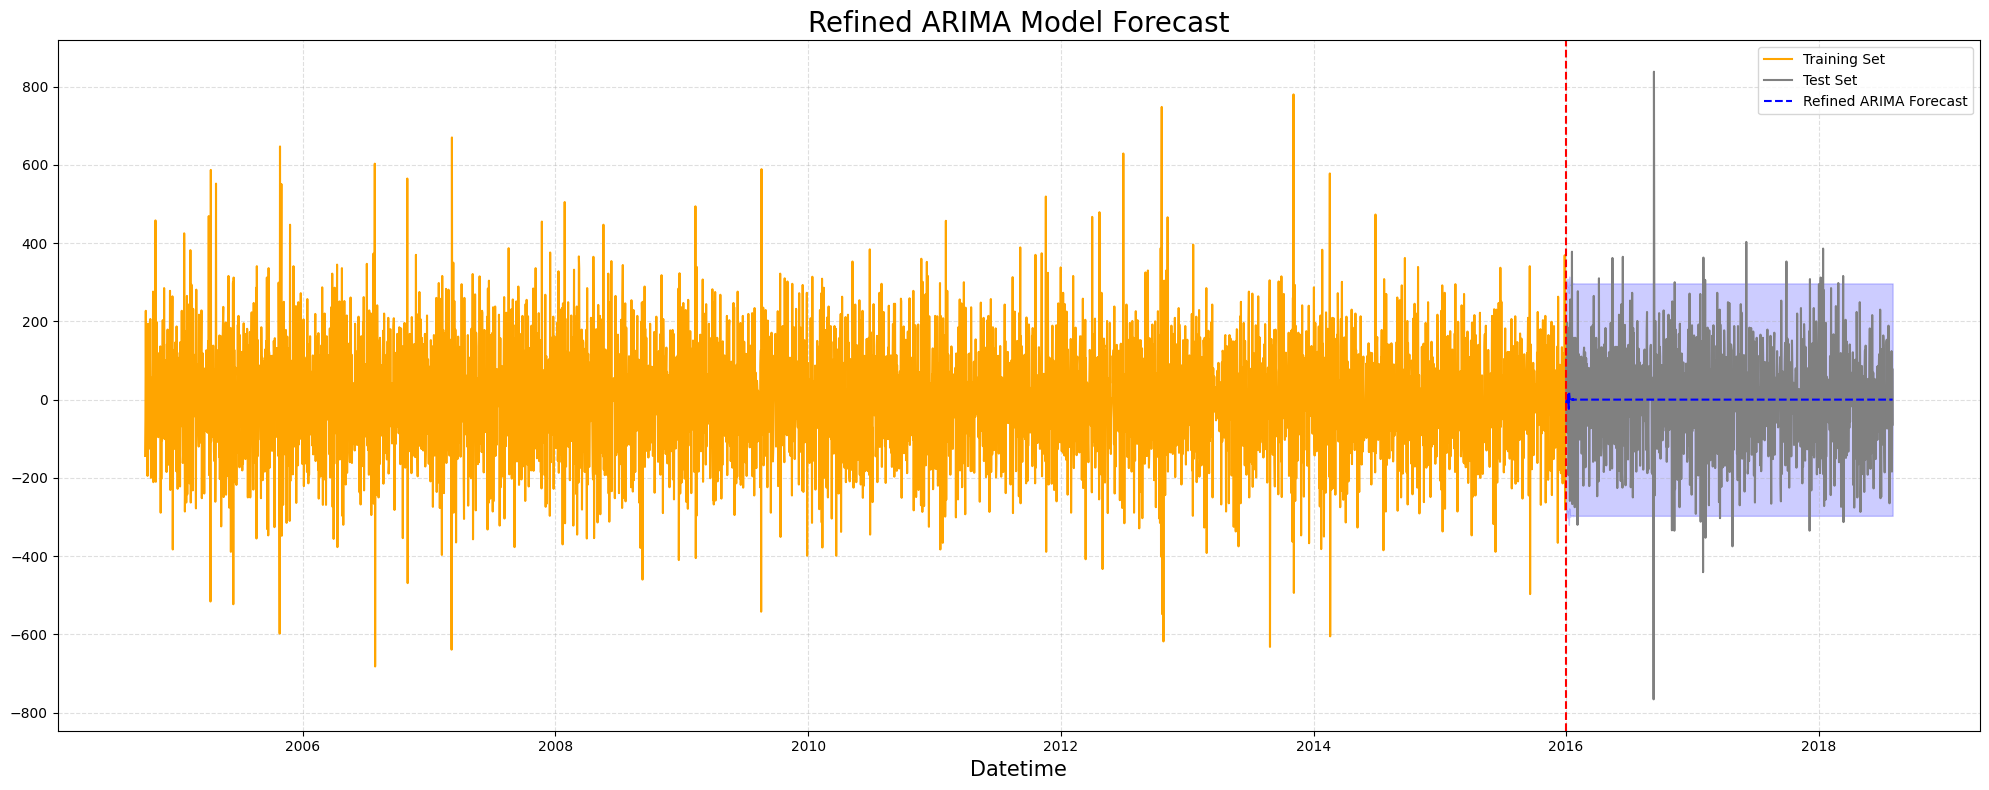

In [71]:
# Try a refined model with adjusted parameters
refined_model = SARIMAX(
    df_train['AEP_MW_seasonal_diff'],
    order=(3, 0, 1),  # Adjust ARIMA (p, d, q) to (3, 0, 1)
    seasonal_order=(1, 0, 1, 12),  # Experiment with seasonal (P, D, Q, m)
    enforce_stationarity=False,
    enforce_invertibility=False,
)

# Fit the refined model
refined_model_fit = refined_model.fit(disp=False)

# Print summary of the refined model
print(refined_model_fit.summary())

# Plot diagnostics to check residuals
refined_model_fit.plot_diagnostics(figsize=(15, 10))
plt.show()

# Forecast future values
forecast_refined = refined_model_fit.get_forecast(steps=len(df_test))
forecast_mean = forecast_refined.predicted_mean
forecast_conf_int = forecast_refined.conf_int()

# Plot the predictions along with actual values
plt.figure(figsize=(20, 8))
plt.plot(df_train['AEP_MW_seasonal_diff'], label='Training Set', color='orange')
plt.plot(df_test['AEP_MW_seasonal_diff'], label='Test Set', color='grey')
plt.plot(df_test.index, forecast_mean, label='Refined ARIMA Forecast', color='blue', linestyle='--')
plt.fill_between(df_test.index, forecast_conf_int.iloc[:, 0], forecast_conf_int.iloc[:, 1], color='blue', alpha=0.2)
plt.axvline(pd.to_datetime('2016-01-01'), color='red', ls='--', lw=1.5)
plt.title('Refined ARIMA Model Forecast', fontsize=20)
plt.xlabel('Datetime', fontsize=15)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

In [72]:
# Extract residuals from the refined model
residuals = refined_model_fit.resid

# Perform the Ljung-Box test
lb_test = acorr_ljungbox(residuals, lags=[10], return_df=True)

# Display the test results
print("Ljung-Box Test Results:")
print(lb_test)

Ljung-Box Test Results:
       lb_stat     lb_pvalue
10  139.155266  6.277807e-25


In [73]:
refined_model_v2 = SARIMAX(
    df_train['AEP_MW_seasonal_diff'],
    order=(3, 0, 2),  # Adjust ARIMA (p, d, q)
    seasonal_order=(1, 0, 2, 12),  # Adjust seasonal (P, D, Q, m)
    enforce_stationarity=False,
    enforce_invertibility=False,
)

# Fit the refined model
refined_model_fit_v2 = refined_model_v2.fit(disp=False)

# Ljung-Box Test on new residuals
residuals_v2 = refined_model_fit_v2.resid
lb_test_v2 = acorr_ljungbox(residuals_v2, lags=[10], return_df=True)

# Display results
print("Refined Model Ljung-Box Test Results:")
print(lb_test_v2)


Refined Model Ljung-Box Test Results:
       lb_stat     lb_pvalue
10  136.974552  1.755148e-24


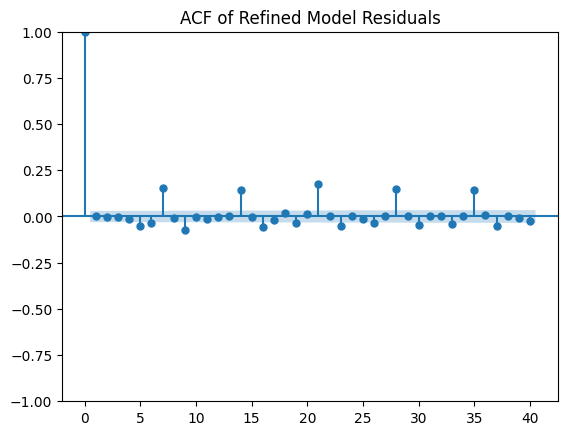

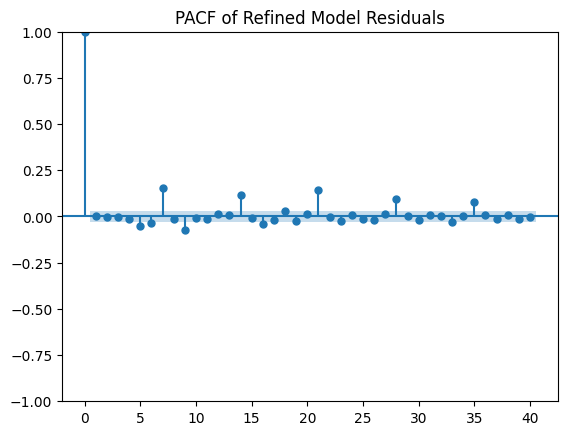

In [74]:
# ACF and PACF of residuals
plot_acf(residuals_v2, lags=40)
plt.title('ACF of Refined Model Residuals')
plt.show()

plot_pacf(residuals_v2, lags=40, method='ywm')
plt.title('PACF of Refined Model Residuals')
plt.show()


In [75]:
# Fit another refined model
refined_model_v3 = SARIMAX(
    df_train['AEP_MW_seasonal_diff'],
    order=(3, 1, 2),  # Adjusted ARIMA order
    seasonal_order=(1, 0, 2, 12),  # Adjusted seasonal order
    enforce_stationarity=False,
    enforce_invertibility=False,
)

# Fit the model
refined_model_fit_v3 = refined_model_v3.fit(disp=False)

# Perform Ljung-Box test
residuals_v3 = refined_model_fit_v3.resid
lb_test_v3 = acorr_ljungbox(residuals_v3, lags=[10], return_df=True)

# Display results
print("Refined Model (v3) Ljung-Box Test Results:")
print(lb_test_v3)


/home/bern/.local/lib/python3.10/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


Refined Model (v3) Ljung-Box Test Results:
       lb_stat     lb_pvalue
10  196.718974  7.796704e-37
